# Linear algebra 4: Determinants

*Learning path: linear algebra, part 4 of 9.* [Index](README.md) · Previous: [Vector spaces](03-vector-spaces.ipynb) · Next: [Orthogonality](05-orthogonality.ipynb)

One number decides whether a square system $Ax = b$ has exactly one solution, whether a matrix can be undone, by how
much a transformation scales areas and volumes, and whether it flips space over like a mirror. That number is the
**determinant**. This lesson defines it by three simple rules, computes it the fast way (elimination) and the slow way
(cofactors), and uses it for areas, volumes and a change of variables.

**Who this is for.** You know matrices as transformations ([lesson 1](01-vectors-and-matrices.ipynb)) and elimination
([lesson 2](02-linear-systems.ipynb)).

**What you will be able to do afterwards:**

1. interpret $\det A$ as a signed area or volume scale factor;
2. compute determinants by elimination (product of the pivots) and by cofactor expansion;
3. use the rules $\det(AB) = \det A\det B$, $\det A^T = \det A$ and what row operations do;
4. decide invertibility with the determinant, and use Cramer's rule and the triangle-area formula.

Plan about an hour.

## 1. Area and orientation

The unit square, spanned by $[1\ 0]$ and $[0\ 1]$, is turned by $A$ into the parallelogram spanned by the two columns
of $A$. Its area is $|\det A|$, where for a $2\times2$ matrix

$$\det\begin{pmatrix} a & b\\ c & d\end{pmatrix} = ad - bc.$$

For $A = [3\ 1;\ 1\ 2]$ the area is $6 - 1 = 5$. The plot shows the outline of the unit square and of its image, traced
as in lesson 1, section 4 (axes: the coordinates $x$ and $y$):

5

> `det`: Determinant.

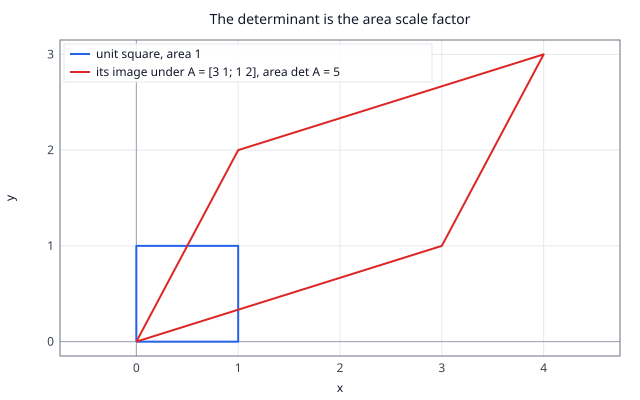

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
A = [3 1; 1 2];
det(A)
c(z) := (abs(z) - abs(z - 1) + 1)/2;
sq = [c(s) - c(s - 2); c(s - 1) - c(s - 3)];
im = A*sq;
p = show(parametric(sq(1), sq(2), s, 0, 4), parametric(im(1), im(2), s, 0, 4));
p = legend(p, "unit square, area 1", "its image under A = [3 1; 1 2], area det A = 5");
labels(title(p, "The determinant is the area scale factor"), "x", "y")

Why $ad - bc$? The parallelogram fits in an $(a + b)\times(c + d)$ rectangle; cutting off two triangles of area $ac/2$,
two of area $bd/2$ and two rectangles of area $bc$ leaves $(a+b)(c+d) - ac - bd - 2bc = ad - bc$.

The **sign** says whether the transformation keeps orientation: going from column 1 to column 2 counterclockwise
(positive) or clockwise (negative, like a mirror). Swapping the columns flips it:

In [2]:
det([1 3; 2 1])
det([0 1; 1 0])

-5

> `det`: Determinant.

-1

> `det`: Determinant.

In three dimensions $|\det A|$ is the **volume** of the box (parallelepiped) spanned by the columns, and it equals the
triple product $(u \times v)\cdot w$ of lesson 1:

In [3]:
det([1 0 1; 2 4 0; 3 5 6])
dot(cross([1 2 3], [0 4 5]), [1 0 6])

22

> `det`: Determinant.

22

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

**Try this.** Find the area of the parallelogram spanned by $[4\ 3]$ and $[1\ 2]$ by hand, then check.

## 2. Three rules determine everything

The determinant of an $n\times n$ matrix is the unique function of its rows with these three properties:

1. $\det I = 1$ (the unit cube has volume 1);
2. exchanging two rows flips the sign;
3. it is linear in each row separately: scaling a row by $t$ scales $\det$ by $t$, and a row that is a sum splits into
   a sum of two determinants.

Everything else follows. Two equal rows give $\det = 0$ (exchanging them changes nothing yet flips the sign).
Subtracting a multiple of one row from another **changes nothing** (split by rule 3: the extra piece has two
proportional rows). So elimination does not change the determinant, except for a sign per row exchange, and for a
triangular matrix the determinant is the product of the diagonal. Hence the fast way:

$$\det A = \pm(\text{product of the pivots}).$$

In [4]:
A3 = [2 1 1; 4 -6 0; -2 7 2];
[L, U, P] = lu(A3)
det(A3)

L = [   1, 0, 0;
  1/2, 1, 0;
 -1/2, 1, 1]
U = [4, -6, 0;
 0,  4, 1;
 0,  0, 1]
P = [0, 1, 0;
 1, 0, 0;
 0, 0, 1]
-16

> `det`: Determinant.

The pivots are $4$, $4$, $1$, with product 16, and `lu` made one row exchange (the $P$ swaps rows 1 and 2), so
$\det A_3 = -16$. Elimination costs about $n^3/3$ operations, which is how computers find determinants.

More consequences, worth memorizing:

* $\det(AB) = \det A \cdot \det B$ (scale factors multiply);
* $\det(A^{-1}) = 1/\det A$;
* $\det(A^T) = \det A$ (so the rules hold for columns too);
* $\det(tA) = t^n\det A$ for an $n\times n$ matrix (every row is scaled).

In [5]:
det(A3*A3)
det(inv(A3))
det(transpose(A3))
det(5*A3)

256

> `det`: Determinant.

-1/16

> `det`: Determinant.

-16

> `det`: Determinant.

-2000

> `det`: Determinant.

**Try this.** Without computing, what is $\det$ of $[1\ 2\ 3;\ 4\ 5\ 6;\ 1\ 2\ 3]$? What is $\det(2I)$ for the
$3\times3$ identity?

## 3. The big formula and cofactors

Expanding with rule 3 row by row gives an explicit formula: a sum over all ways to pick one entry in each row and each
column, with signs. For $3\times3$ there are $3! = 6$ terms:

In [6]:
det([a1 a2 a3; b1 b2 b3; c1 c2 c3])

a1*b2*c3-a1*b3*c2-a2*b1*c3+a2*b3*c1+a3*b1*c2-a3*b2*c1

> `det`: Determinant.

Grouping the terms by the entries of the first row gives the **cofactor expansion**:

$$\det A = a_{11}C_{11} + a_{12}C_{12} + a_{13}C_{13}, \qquad C_{ij} = (-1)^{i+j}\det(M_{ij}),$$

where $M_{ij}$ is $A$ with row $i$ and column $j$ removed. You may expand along any row or column; pick one with many
zeros. For $[1\ 0\ 1;\ 2\ 4\ 0;\ 3\ 5\ 6]$ along the first row: $1\cdot(24 - 0) - 0 + 1\cdot(10 - 12) = 22$, as in
section 1.

The big formula has $n!$ terms: for $n = 20$ that is about $2.4\cdot10^{18}$, while elimination needs about 2700
operations. Cofactors are for small matrices, proofs and formulas, not for computing.

A classic formula from cofactors: the **Vandermonde determinant**, which decides when a polynomial can pass through
given points.

In [7]:
factor(det([1 a a^2; 1 b b^2; 1 c c^2]))

-(a-b)*(a-c)*(b-c)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

It is zero exactly when two of $a, b, c$ coincide: through three points with *different* $x$ coordinates there is
exactly one parabola.

**Try this.** Compute $\det[2\ 0\ 0;\ 7\ 3\ 0;\ 1\ 8\ 5]$ by hand. (Triangular!)

## 4. Invertibility, Cramer's rule and the inverse

For a square matrix these all say the same thing:

$$\det A \ne 0 \iff A \text{ is invertible} \iff \text{rank } n \iff \text{independent columns} \iff Ax = b \text{ has exactly one solution}.$$

If $\det A = 0$ the transformation squashes space into a lower dimension (area or volume 0), and nothing can undo that.

In [8]:
det([1 2 3; 4 5 6; 7 8 9])
rank([1 2 3; 4 5 6; 7 8 9])

0

> `det`: Determinant.

2

> `rank` (see `rref`): Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

**Cramer's rule** writes the solution of $Ax = b$ with determinants: $x_j = \det B_j / \det A$, where $B_j$ is $A$ with
column $j$ replaced by $b$. For $x + 3y = 5$, $2x - y = 3$ (lesson 2):

In [9]:
A = [1 3; 2 -1];
simplify(det([5 3; 3 -1])/det(A))
simplify(det([1 5; 2 3])/det(A))

2

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

1

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

$x = 2$, $y = 1$, as before. The same idea gives the inverse: $A^{-1} = C^T/\det A$ with the matrix $C$ of cofactors,
which for $2\times2$ is the formula of lesson 1. Like the big formula, Cramer's rule is beautiful for $2\times2$ and
$3\times3$ and for theory, and far too slow beyond that.

**Try this.** Solve $2x + y = 3$, $5x + 3y = 7$ with Cramer's rule.

## 5. Determinants at work

**Area of a triangle** with corners $(x_1, y_1)$, $(x_2, y_2)$, $(x_3, y_3)$: half the determinant below (subtract the
first row from the others and you get the parallelogram of two sides):

In [10]:
det([x1 y1 1; x2 y2 1; x3 y3 1])/2
simplify(det([0 0 1; 4 0 1; 0 3 1])/2)

(x1*y2-x1*y3-x2*y1+x2*y3+x3*y1-x3*y2)/2
6

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The 3-4-5 right triangle has area 6. The sign tells whether the corners are listed counterclockwise, which is how
computer graphics decides which side of a triangle faces the camera.

**Change of variables.** In [multivariable lesson 5](../multivariable/05-multiple-integrals.ipynb) polar coordinates
needed $dx\,dy = r\,dr\,d\theta$. The factor $r$ is a determinant: the area scale factor of the map
$(r, t) \mapsto (r\cos t, r\sin t)$, computed from its Jacobian matrix of partial derivatives.

In [11]:
J = jacobian([r*cos(t), r*sin(t)], [r t])
simplify(det(J))

[cos(t), -r*sin(t);
 sin(t),  r*cos(t)]

> Row i of the Jacobian holds the partial derivatives of the i-th function. It is the best linear approximation of the map near a point; for a change of variables its determinant is the local area (or volume) scale factor, as in dx dy = |det J| dr dθ.

r

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

A small $dr \times dt$ rectangle becomes a curved patch of area about $r\,dr\,dt$: far from the origin the patches are
bigger.

**Try this.** Find the area of the triangle with corners $(1, 1)$, $(4, 2)$, $(2, 5)$.

## Exercises

1. **Volume.** Find the volume of the box spanned by $[1\ 1\ 0]$, $[0\ 1\ 1]$, $[1\ 0\ 1]$.
2. **Rules.** If $\det A = 3$ for a $4\times4$ matrix, find $\det(2A)$, $\det(A^{-1})$, $\det(A^2)$ and $\det(A^T A)$.
3. **When is it singular?** For which $t$ is $[t\ 1\ 0;\ 1\ t\ 1;\ 0\ 1\ t]$ not invertible? (Use `solve` on the
   determinant.)
4. **Pivots.** Find $\det[2\ 1\ 0;\ 1\ 2\ 1;\ 0\ 1\ 2]$ as the product of the pivots from `lu`, and by cofactors.
5. **Rotations and reflections.** Show that every rotation matrix has determinant 1 and every reflection
   determinant $-1$. What does that mean geometrically?

## Hints and answers

* **Section 1, Try this.** $4\cdot2 - 1\cdot3 = 5$.
* **Section 2, Try this.** Two equal rows: 0. $\det(2I) = 2^3 = 8$.
* **Section 3, Try this.** Product of the diagonal: $2\cdot3\cdot5 = 30$.
* **Section 4, Try this.** $\det A = 1$; $x = \det[3\ 1;\ 7\ 3] = 2$, $y = \det[2\ 3;\ 5\ 7] = -1$.
* **Section 5, Try this.** `det([1 1 1; 4 2 1; 2 5 1])/2` $= 11/2$.
* **Exercise 1.** `det([1 0 1; 1 1 0; 0 1 1])` $= 2$.
* **Exercise 2.** $2^4\cdot3 = 48$, $1/3$, $9$, $9$.
* **Exercise 3.** $\det = t^3 - 2t = t(t^2 - 2)$: $t = 0$ or $t = \pm\sqrt2$.
* **Exercise 4.** Pivots $2$, $3/2$, $4/3$; product 4.
* **Exercise 5.** $\cos^2 t + \sin^2 t = 1$; a reflection such as $[1\ 0;\ 0\ {-1}]$ gives $-1$. Rotations keep area and
  orientation; reflections keep area but flip orientation.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), chapter 5.
2. D. C. Lay, S. R. Lay and J. J. McDonald, *Linear Algebra and Its Applications*, 6th ed., Pearson (2021), chapter 3.
3. G. Cramer, *Introduction à l'analyse des lignes courbes algébriques*, Geneva (1750), appendix: the rule.
4. T. Muir, *The Theory of Determinants in the Historical Order of Development*, Macmillan (1906 to 1923).